# Joint Autocorrelation Analysis

Compare temporal coherence of joint angle trajectories across datasets. For each joint, compute the autocorrelation function averaged across clips, then summarize with the autocorrelation time (lag at which autocorrelation drops below 1/e).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from pathlib import Path

from scamper.analysis.discriminator.data_loading import (
    load_h5_dataset,
    list_h5_datasets,
)

# ============ CONFIGURATION ============
DATASET_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_goldenrodent_jax_fullclips_latents.h5"
REFERENCE_DATASET = "encoder_decoder_qpos"
JOINT_ANGLE_START = 7
EXCLUDE_DATASETS = {"original_qpos"}
SAVE_DIR = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation")
REMOVE_FALLEN = True

In [2]:
import os


def find_fall_timesteps(qpos_data, mj_model, skull_body_id):
    """Find the first timestep where skull z < 0 for each clip.

    Args:
        qpos_data: Shape (num_clips, num_steps, qpos_dim).
        mj_model: MuJoCo model.
        skull_body_id: Body ID of the skull.

    Returns:
        1-D array of shape (num_clips,). Each value is the first timestep
        where the skull goes below ground, or num_steps if it never falls.
    """
    import mujoco

    num_clips, num_steps, _ = qpos_data.shape
    mj_data = mujoco.MjData(mj_model)

    fall_steps = np.full(num_clips, num_steps, dtype=np.intp)
    for clip_idx in range(num_clips):
        for step_idx in range(num_steps):
            mj_data.qpos[:] = qpos_data[clip_idx, step_idx]
            mujoco.mj_forward(mj_model, mj_data)
            if mj_data.xpos[skull_body_id, 2] < 0:
                fall_steps[clip_idx] = step_idx
                break

    return fall_steps


def load_and_detect_falls(h5_path, dataset_names, joint_angle_start):
    """Load datasets and find per-clip fall timesteps for each dataset.

    Timesteps at and after the first fall are excluded per clip per dataset.
    Different datasets may have different amounts of data removed.

    Returns:
        qpos_dict: name -> (num_clips, num_steps, num_joints) joint angle data.
        valid_lengths_dict: name -> (num_clips,) valid timesteps per clip.
    """
    full_qpos = {}
    for name in dataset_names:
        full_qpos[name] = load_h5_dataset(h5_path, name)
        print(f"  {name}: {full_qpos[name].shape}")

    num_clips = full_qpos[dataset_names[0]].shape[0]
    num_steps = full_qpos[dataset_names[0]].shape[1]
    total_points_per_ds = num_clips * num_steps

    valid_lengths_dict = {}

    if REMOVE_FALLEN:
        import mujoco
        from vnl_playground.tasks.rodent import imitation

        os.environ.setdefault("MUJOCO_GL", "egl")
        os.environ.setdefault("PYOPENGL_PLATFORM", "egl")

        env = imitation.Imitation()
        mj_model = env.mj_model
        del env
        skull_body_id = mujoco.mj_name2id(
            mj_model, mujoco.mjtObj.mjOBJ_BODY, "skull-rodent"
        )

        print(f"\nDetecting falls (skull z < 0) via FK...")
        total_removed = 0
        for name in dataset_names:
            fall_steps = find_fall_timesteps(full_qpos[name], mj_model, skull_body_id)
            valid_lengths_dict[name] = fall_steps

            removed = int(np.sum(num_steps - fall_steps))
            pct = 100.0 * removed / total_points_per_ds
            total_removed += removed

            n_fallen = int(np.sum(fall_steps < num_steps))
            print(
                f"    {name}: {n_fallen}/{num_clips} clips with falls, "
                f"{removed}/{total_points_per_ds} timesteps removed ({pct:.1f}%)"
            )

        grand_total = total_points_per_ds * len(dataset_names)
        grand_pct = 100.0 * total_removed / grand_total if grand_total > 0 else 0.0
        print(
            f"\n  Total: {total_removed}/{grand_total} timesteps removed ({grand_pct:.1f}%)"
        )
    else:
        for name in dataset_names:
            valid_lengths_dict[name] = np.full(num_clips, num_steps, dtype=np.intp)

    qpos_dict = {}
    for name in dataset_names:
        qpos_dict[name] = full_qpos[name][:, :, joint_angle_start:]

    return qpos_dict, valid_lengths_dict

In [3]:
# Load raw qpos for autocorrelation (need full time series, not transitions)
available = list_h5_datasets(DATASET_PATH)
ac_generated_names = [
    ds
    for ds in available
    if ds.endswith("_qpos")
    and ds != REFERENCE_DATASET
    and ds not in EXCLUDE_DATASETS
    and ds != "prior_predicted_logvar_qpos"
]

ac_label_map = {
    "encoder_decoder_qpos": "Imitation",
    "prior_deterministic_qpos": "$\\sigma$=0.00",
    "prior_logvar_-4_qpos": "$\\sigma$=0.14",
    "prior_logvar_-3_qpos": "$\\sigma$=0.22",
    "prior_logvar_-2_qpos": "$\\sigma$=0.37",
    "prior_logvar_-1_qpos": "$\\sigma$=0.61",
    "prior_logvar_-0.5_qpos": "$\\sigma$=0.78",
    "prior_logvar_0_qpos": "$\\sigma$=1.00",
}

ac_datasets = [REFERENCE_DATASET] + ac_generated_names

ac_qpos, ac_valid_lengths = load_and_detect_falls(
    DATASET_PATH, ac_datasets, JOINT_ANGLE_START
)

  encoder_decoder_qpos: (842, 490, 74)
  prior_deterministic_qpos: (842, 490, 74)
  prior_logvar_-0.5_qpos: (842, 490, 74)
  prior_logvar_-1_qpos: (842, 490, 74)
  prior_logvar_-2_qpos: (842, 490, 74)
  prior_logvar_-3_qpos: (842, 490, 74)
  prior_logvar_-4_qpos: (842, 490, 74)
  prior_logvar_0_qpos: (842, 490, 74)

Detecting falls (skull z < 0) via FK...
    encoder_decoder_qpos: 9/842 clips with falls, 1886/412580 timesteps removed (0.5%)
    prior_deterministic_qpos: 16/842 clips with falls, 3124/412580 timesteps removed (0.8%)
    prior_logvar_-0.5_qpos: 11/842 clips with falls, 1625/412580 timesteps removed (0.4%)
    prior_logvar_-1_qpos: 6/842 clips with falls, 1243/412580 timesteps removed (0.3%)
    prior_logvar_-2_qpos: 9/842 clips with falls, 1629/412580 timesteps removed (0.4%)
    prior_logvar_-3_qpos: 13/842 clips with falls, 3190/412580 timesteps removed (0.8%)
    prior_logvar_-4_qpos: 14/842 clips with falls, 2948/412580 timesteps removed (0.7%)
    prior_logvar_0_qpos

In [4]:
def compute_autocorrelation_per_clip(
    joints: np.ndarray, max_lag: int, valid_lengths: np.ndarray = None
) -> np.ndarray:
    """Compute autocorrelation per clip (averaged across joints).

    Args:
        joints: Shape (num_clips, num_steps, num_joints).
        max_lag: Maximum lag to compute.
        valid_lengths: Optional (num_clips,) array of valid timesteps per clip.
            If None, all timesteps are used. When provided, timesteps at and
            beyond each clip's valid length are excluded from all statistics.

    Returns:
        Per-clip autocorrelation curves of shape (num_clips, max_lag + 1).
        Entries are NaN for clips/lags without sufficient valid data.
    """
    num_clips, num_steps, num_joints = joints.shape
    max_lag = min(max_lag, num_steps - 1)

    if valid_lengths is None:
        valid_lengths = np.full(num_clips, num_steps, dtype=np.intp)

    # Validity mask per timestep: (num_clips, num_steps, 1)
    step_idx = np.arange(num_steps)[np.newaxis, :]  # (1, num_steps)
    mask = (step_idx < valid_lengths[:, np.newaxis]).astype(
        np.float64
    )  # (num_clips, num_steps)
    mask_3d = mask[:, :, np.newaxis]  # (num_clips, num_steps, 1)

    # Mean over valid steps only
    valid_count = mask.sum(axis=1)  # (num_clips,)
    valid_sum = (joints * mask_3d).sum(axis=1)  # (num_clips, num_joints)
    mean = valid_sum / np.maximum(
        valid_count[:, np.newaxis], 1
    )  # (num_clips, num_joints)

    # Center and zero out invalid steps
    centered = (joints - mean[:, np.newaxis, :]) * mask_3d

    # Variance over valid steps
    var = (centered**2).sum(axis=1) / np.maximum(valid_count[:, np.newaxis], 1)

    ac_curves = np.full((num_clips, num_joints, max_lag + 1), np.nan)

    for lag in range(max_lag + 1):
        if lag == 0:
            valid_clip = valid_count >= 2
            ac_curves[valid_clip, :, 0] = 1.0
        else:
            # Number of valid pairs per clip for this lag
            pair_count = np.maximum(valid_lengths - lag, 0)  # (num_clips,)

            # Covariance (invalid steps are zeroed in centered, so only valid pairs contribute)
            cov = (centered[:, : num_steps - lag, :] * centered[:, lag:, :]).sum(axis=1)
            cov = cov / np.maximum(pair_count[:, np.newaxis], 1)

            ac = np.where(var > 1e-12, cov / var, 0.0)

            has_pairs = pair_count >= 1
            ac_curves[has_pairs, :, lag] = ac[has_pairs]

    # Average across joints: (num_clips, max_lag + 1)
    return np.nanmean(ac_curves, axis=1)


def autocorrelation_time(ac_curve: np.ndarray, threshold: float = 1.0 / np.e) -> float:
    """Find the lag at which autocorrelation drops below threshold."""
    below = np.where(ac_curve < threshold)[0]
    return int(below[0]) if len(below) > 0 else len(ac_curve) - 1


MAX_LAG = 200

# Compute per-clip autocorrelation, then mean/std across clips
ac_stats = {}  # name -> {"mean": ..., "std": ...}
ac_times = {}
ac_times_std = {}

for name in ac_datasets:
    per_clip = compute_autocorrelation_per_clip(
        ac_qpos[name], MAX_LAG, ac_valid_lengths[name]
    )
    mean_curve = np.nanmean(per_clip, axis=0)
    std_curve = np.nanstd(per_clip, axis=0)

    ac_stats[name] = {"mean": mean_curve, "std": std_curve}
    ac_times[name] = autocorrelation_time(mean_curve)

    # Per-clip autocorrelation times for uncertainty (skip clips with < 2 valid steps)
    valid_mask = ~np.isnan(per_clip[:, 0])
    per_clip_times = np.array([autocorrelation_time(c) for c in per_clip[valid_mask]])
    ac_times_std[name] = per_clip_times.std() if len(per_clip_times) > 0 else 0.0

    label = ac_label_map.get(name, name)
    print(
        f"{label}: autocorrelation time = {ac_times[name]} +/- {ac_times_std[name]:.1f} steps"
    )

/tmp/ipykernel_521495/901338107.py:57: RuntimeWarning: Mean of empty slice
  return np.nanmean(ac_curves, axis=1)


Imitation: autocorrelation time = 58 +/- 14.9 steps
$\sigma$=0.00: autocorrelation time = 54 +/- 14.3 steps
$\sigma$=0.78: autocorrelation time = 47 +/- 11.9 steps
$\sigma$=0.61: autocorrelation time = 49 +/- 12.2 steps
$\sigma$=0.37: autocorrelation time = 51 +/- 12.8 steps
$\sigma$=0.22: autocorrelation time = 53 +/- 13.6 steps
$\sigma$=0.14: autocorrelation time = 53 +/- 14.5 steps
$\sigma$=1.00: autocorrelation time = 44 +/- 11.1 steps


/tmp/ipykernel_521495/2819143503.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("viridis", n_gen)


Saved autocorrelation curves


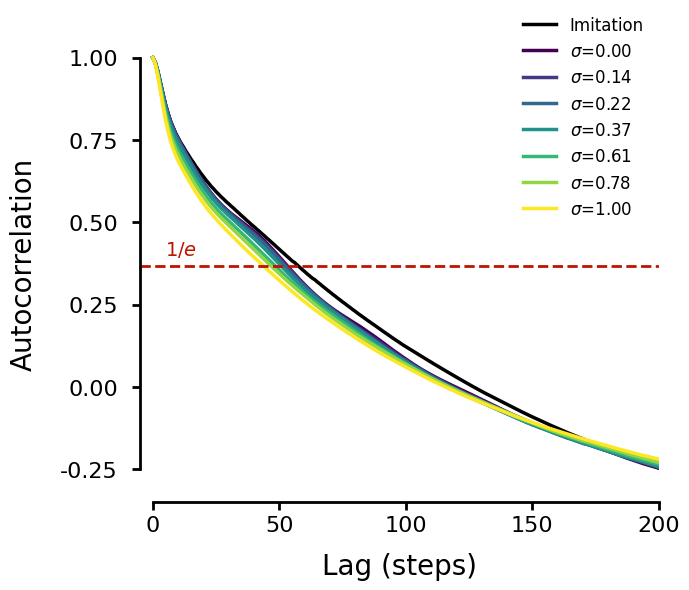

In [5]:
# Color palette: Imitation in black, generated in a colormap
import matplotlib.cm as cm

n_gen = len(ac_generated_names)
cmap = cm.get_cmap("viridis", n_gen)


# Sort generated names by sigma value
def ac_sort_key(name):
    lbl = ac_label_map.get(name, "")
    val = lbl.replace("$\\sigma$=", "")
    try:
        return float(val)
    except ValueError:
        return 999.0


ac_gen_sorted = sorted(ac_generated_names, key=ac_sort_key)

# Assign colors
ac_colors = {REFERENCE_DATASET: "black"}
for i, name in enumerate(ac_gen_sorted):
    ac_colors[name] = cmap(i)

# Plot order: enc-dec first, then sorted generated
ac_plot_order = [REFERENCE_DATASET] + ac_gen_sorted

lags = np.arange(MAX_LAG + 1)
red_color = tuple(c / 255 for c in (189, 19, 0))

fig, ax = plt.subplots(figsize=(7, 6))

for name in ac_plot_order:
    label = ac_label_map.get(name, name)
    mean = ac_stats[name]["mean"]
    color = ac_colors[name]

    ax.plot(lags, mean, linewidth=2.5, color=color, label=label)

ax.set_xlabel("Lag (steps)", fontsize=20, labelpad=12)
ax.set_ylabel("Autocorrelation", fontsize=20, labelpad=16)
ax.tick_params(labelsize=16, width=2, length=6)
ax.tick_params(axis="y", pad=10)
ax.set_ylim(-0.35, 1.1)
ax.set_xlim(-5, MAX_LAG)

# Set y ticks
base_yticks = [-0.25, 0.0, 0.25, 0.5, 0.75, 1.0]
ax.set_yticks(base_yticks)
ax.set_yticklabels([f"{t:.2f}" for t in base_yticks])

sns.despine(ax=ax)

# Trim spines to tick range — they won't meet since x starts at 0 but y starts at -0.25
xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax.spines["left"].set_bounds(base_yticks[0], base_yticks[-1])

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

# 1/e threshold line with label sitting above it
ax.axhline(1.0 / np.e, color=red_color, linestyle="--", alpha=1.0, linewidth=2)
ax.text(5, 1.0 / np.e + 0.02, "$1/e$", color=red_color, fontsize=14, va="bottom")

ax.legend(fontsize=12, frameon=False, loc="upper right", bbox_to_anchor=(1.0, 1.05))

plt.tight_layout()
SAVE_DIR.mkdir(parents=True, exist_ok=True)
for fmt in ("pdf", "svg", "png"):
    fig.savefig(
        SAVE_DIR / f"autocorrelation_curves.{fmt}", bbox_inches="tight", dpi=150
    )
print(f"Saved autocorrelation curves")
plt.show()

In [6]:
# Min autocorrelation (mean curve) for each dataset
for name in ac_plot_order:
    label = ac_label_map.get(name, name)
    min_val = ac_stats[name]["mean"].min()
    min_lag = ac_stats[name]["mean"].argmin()
    print(f"{label:>20s}: min autocorrelation = {min_val:.4f} at lag {min_lag}")

           Imitation: min autocorrelation = -0.2464 at lag 200
       $\sigma$=0.00: min autocorrelation = -0.2464 at lag 200
       $\sigma$=0.14: min autocorrelation = -0.2421 at lag 200
       $\sigma$=0.22: min autocorrelation = -0.2440 at lag 200
       $\sigma$=0.37: min autocorrelation = -0.2411 at lag 200
       $\sigma$=0.61: min autocorrelation = -0.2351 at lag 200
       $\sigma$=0.78: min autocorrelation = -0.2298 at lag 200
       $\sigma$=1.00: min autocorrelation = -0.2191 at lag 200


/tmp/ipykernel_521495/1082365622.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=ac_labels, x=ac_values, palette=colors, ax=ax)


Saved autocorrelation time bar plot


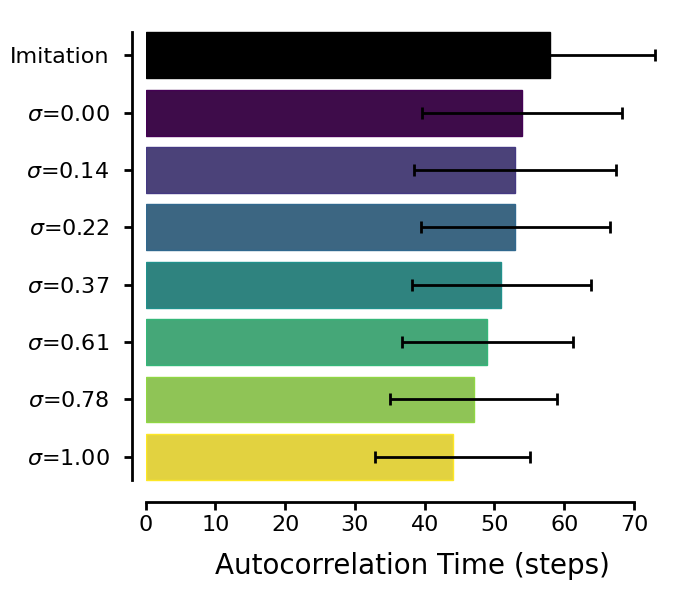

In [7]:
# Bar plot of autocorrelation times
ac_bar_order = [REFERENCE_DATASET] + ac_gen_sorted
ac_bar_order = [n for n in ac_bar_order if n in ac_times]

ac_labels = [ac_label_map.get(n, n) for n in ac_bar_order]
ac_values = [ac_times[n] for n in ac_bar_order]
ac_stds = [ac_times_std[n] for n in ac_bar_order]
colors = [ac_colors[n] for n in ac_bar_order]

fig, ax = plt.subplots(figsize=(7, 6))

sns.barplot(y=ac_labels, x=ac_values, palette=colors, ax=ax)

# Remove black outlines — set edgecolor to match facecolor
for patch, c in zip(ax.patches, colors):
    patch.set_edgecolor(c)

# Add error bars
bar_positions = sorted([patch.get_y() + patch.get_height() / 2 for patch in ax.patches])
ax.errorbar(
    ac_values,
    bar_positions,
    xerr=ac_stds,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

ax.set_xlabel("Autocorrelation Time (steps)", fontsize=20, labelpad=12)
ax.set_ylabel("")
ax.tick_params(labelsize=16, width=2, length=6)
ax.tick_params(axis="y", pad=10)

sns.despine(ax=ax)
ax.spines["left"].set_position(("outward", 10))

xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])

bar_positions_raw = sorted([p.get_y() for p in ax.patches])
ax.spines["left"].set_bounds(
    bar_positions_raw[0], bar_positions_raw[-1] + ax.patches[0].get_height()
)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()
for fmt in ("pdf", "svg", "png"):
    fig.savefig(SAVE_DIR / f"autocorrelation_time.{fmt}", bbox_inches="tight")
print(f"Saved autocorrelation time bar plot")
plt.show()

# Joint Autocorrelation Analysis (Distill)

Compare temporal coherence of joint angle trajectories across datasets from the distill checkpoint. For each joint, compute the autocorrelation function averaged across clips, then summarize with the autocorrelation time (lag at which autocorrelation drops below 1/e).

In [8]:
# ============ DISTILL CONFIGURATION ============
DISTILL_DATASET_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_PULSE_matchKL_noclamp_49.h5"
DISTILL_REFERENCE_DATASET = "student_encoder_decoder_qpos"

CLAMP_DATASET_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_PULSE_matchKL_clamp_49.h5"
CLAMP_REFERENCE_DATASET = "student_encoder_decoder_qpos"

# Shared label map for both distill checkpoints
distill_ac_label_map = {
    "student_encoder_decoder_qpos": "Student Imitation",
    "teacher_qpos": "Teacher Imitation",
    "encoder_decoder_qpos": "Imitation Rollout",
    "prior_deterministic_qpos": "$\\sigma$=0.00",
    "prior_logvar_-4_qpos": "$\\sigma$=0.14",
    "prior_logvar_-3_qpos": "$\\sigma$=0.22",
    "prior_logvar_-2_qpos": "$\\sigma$=0.37",
    "prior_logvar_-1_qpos": "$\\sigma$=0.61",
    "prior_logvar_-0.5_qpos": "$\\sigma$=0.78",
    "prior_logvar_0_qpos": "$\\sigma$=1.00",
}

# --- PULSE w/o logvar clip ---
print("=== PULSE w/o logvar clip ===")
distill_available = list_h5_datasets(DISTILL_DATASET_PATH)
distill_ac_generated_names = [
    ds
    for ds in distill_available
    if ds.endswith("_qpos")
    and ds != DISTILL_REFERENCE_DATASET
    and ds not in EXCLUDE_DATASETS
    and ds != "prior_predicted_logvar_qpos"
]
distill_ac_datasets = [DISTILL_REFERENCE_DATASET] + distill_ac_generated_names

distill_ac_qpos, distill_valid_lengths = load_and_detect_falls(
    DISTILL_DATASET_PATH, distill_ac_datasets, JOINT_ANGLE_START
)

# --- PULSE w/ logvar clip ---
print("\n=== PULSE w/ logvar clip ===")
clamp_available = list_h5_datasets(CLAMP_DATASET_PATH)
clamp_ac_generated_names = [
    ds
    for ds in clamp_available
    if ds.endswith("_qpos")
    and ds != CLAMP_REFERENCE_DATASET
    and ds not in EXCLUDE_DATASETS
    and ds != "prior_predicted_logvar_qpos"
]
clamp_ac_datasets = [CLAMP_REFERENCE_DATASET] + clamp_ac_generated_names

clamp_ac_qpos, clamp_valid_lengths = load_and_detect_falls(
    CLAMP_DATASET_PATH, clamp_ac_datasets, JOINT_ANGLE_START
)

=== PULSE w/o logvar clip ===
  student_encoder_decoder_qpos: (842, 490, 74)
  prior_deterministic_qpos: (842, 490, 74)
  prior_logvar_-0.5_qpos: (842, 490, 74)
  prior_logvar_-1_qpos: (842, 490, 74)
  prior_logvar_-2_qpos: (842, 490, 74)
  prior_logvar_-3_qpos: (842, 490, 74)
  prior_logvar_-4_qpos: (842, 490, 74)
  prior_logvar_0_qpos: (842, 490, 74)
  teacher_qpos: (842, 490, 74)

Detecting falls (skull z < 0) via FK...
    student_encoder_decoder_qpos: 18/842 clips with falls, 4263/412580 timesteps removed (1.0%)
    prior_deterministic_qpos: 269/842 clips with falls, 65699/412580 timesteps removed (15.9%)
    prior_logvar_-0.5_qpos: 236/842 clips with falls, 63966/412580 timesteps removed (15.5%)
    prior_logvar_-1_qpos: 219/842 clips with falls, 53466/412580 timesteps removed (13.0%)
    prior_logvar_-2_qpos: 219/842 clips with falls, 52029/412580 timesteps removed (12.6%)
    prior_logvar_-3_qpos: 238/842 clips with falls, 56774/412580 timesteps removed (13.8%)
    prior_logvar

In [9]:
# Compute per-clip autocorrelation for distill datasets (PULSE w/o logvar clip)
distill_ac_stats = {}
distill_ac_times = {}
distill_ac_times_std = {}

print("=== PULSE w/o logvar clip ===")
for name in distill_ac_datasets:
    per_clip = compute_autocorrelation_per_clip(
        distill_ac_qpos[name], MAX_LAG, distill_valid_lengths[name]
    )
    mean_curve = np.nanmean(per_clip, axis=0)
    std_curve = np.nanstd(per_clip, axis=0)

    distill_ac_stats[name] = {"mean": mean_curve, "std": std_curve}
    distill_ac_times[name] = autocorrelation_time(mean_curve)

    valid_mask = ~np.isnan(per_clip[:, 0])
    per_clip_times = np.array([autocorrelation_time(c) for c in per_clip[valid_mask]])
    distill_ac_times_std[name] = (
        per_clip_times.std() if len(per_clip_times) > 0 else 0.0
    )

    label = distill_ac_label_map.get(name, name)
    print(
        f"{label}: autocorrelation time = {distill_ac_times[name]} +/- {distill_ac_times_std[name]:.1f} steps"
    )

# Compute per-clip autocorrelation for clamp datasets (PULSE w/ logvar clip)
clamp_ac_stats = {}
clamp_ac_times = {}
clamp_ac_times_std = {}

print("\n=== PULSE w/ logvar clip ===")
for name in clamp_ac_datasets:
    per_clip = compute_autocorrelation_per_clip(
        clamp_ac_qpos[name], MAX_LAG, clamp_valid_lengths[name]
    )
    mean_curve = np.nanmean(per_clip, axis=0)
    std_curve = np.nanstd(per_clip, axis=0)

    clamp_ac_stats[name] = {"mean": mean_curve, "std": std_curve}
    clamp_ac_times[name] = autocorrelation_time(mean_curve)

    valid_mask = ~np.isnan(per_clip[:, 0])
    per_clip_times = np.array([autocorrelation_time(c) for c in per_clip[valid_mask]])
    clamp_ac_times_std[name] = per_clip_times.std() if len(per_clip_times) > 0 else 0.0

    label = distill_ac_label_map.get(name, name)
    print(
        f"{label}: autocorrelation time = {clamp_ac_times[name]} +/- {clamp_ac_times_std[name]:.1f} steps"
    )

=== PULSE w/o logvar clip ===


/tmp/ipykernel_521495/901338107.py:57: RuntimeWarning: Mean of empty slice
  return np.nanmean(ac_curves, axis=1)


Student Imitation: autocorrelation time = 57 +/- 15.3 steps
$\sigma$=0.00: autocorrelation time = 54 +/- 21.0 steps
$\sigma$=0.78: autocorrelation time = 42 +/- 17.6 steps
$\sigma$=0.61: autocorrelation time = 48 +/- 17.8 steps
$\sigma$=0.37: autocorrelation time = 55 +/- 19.3 steps
$\sigma$=0.22: autocorrelation time = 55 +/- 20.2 steps
$\sigma$=0.14: autocorrelation time = 55 +/- 20.4 steps
$\sigma$=1.00: autocorrelation time = 32 +/- 15.2 steps
Teacher Imitation: autocorrelation time = 55 +/- 12.6 steps

=== PULSE w/ logvar clip ===
Student Imitation: autocorrelation time = 57 +/- 15.3 steps
$\sigma$=0.00: autocorrelation time = 64 +/- 17.7 steps
$\sigma$=0.78: autocorrelation time = 64 +/- 14.3 steps
$\sigma$=0.61: autocorrelation time = 64 +/- 15.7 steps
$\sigma$=0.37: autocorrelation time = 65 +/- 17.0 steps
$\sigma$=0.22: autocorrelation time = 64 +/- 17.5 steps
$\sigma$=0.14: autocorrelation time = 64 +/- 17.7 steps
$\sigma$=1.00: autocorrelation time = 62 +/- 13.5 steps
Teache

/tmp/ipykernel_521495/2323152900.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  distill_cmap = cm.get_cmap("viridis", distill_n_gen)


Saved distill autocorrelation curves


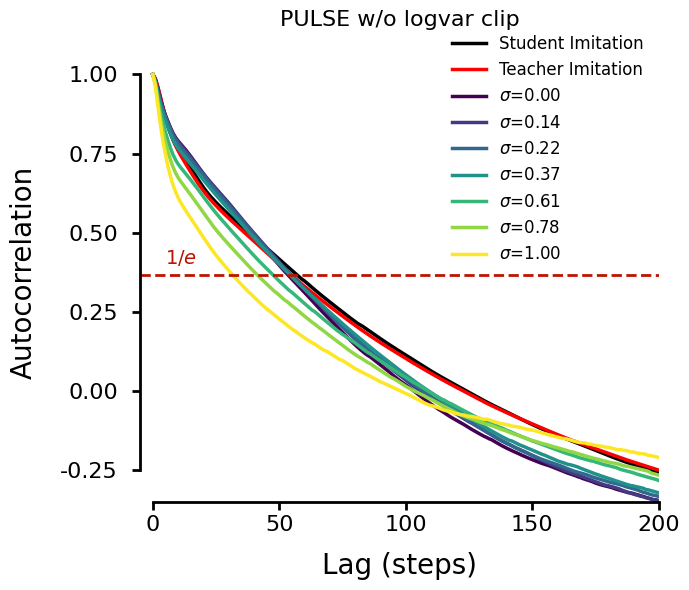

In [10]:
# Color palette: Student Imitation in black, Teacher in red, generated in viridis
import matplotlib.cm as cm

DISTILL_TEACHER_DATASET = "teacher_qpos"

distill_ac_gen_no_teacher = [
    n for n in distill_ac_generated_names if n != DISTILL_TEACHER_DATASET
]
distill_n_gen = len(distill_ac_gen_no_teacher)
distill_cmap = cm.get_cmap("viridis", distill_n_gen)


def distill_ac_sort_key(name):
    lbl = distill_ac_label_map.get(name, "")
    val = lbl.replace("$\\sigma$=", "")
    try:
        return float(val)
    except ValueError:
        return 999.0


distill_ac_gen_sorted = sorted(distill_ac_gen_no_teacher, key=distill_ac_sort_key)

distill_ac_colors = {DISTILL_REFERENCE_DATASET: "black", DISTILL_TEACHER_DATASET: "red"}
for i, name in enumerate(distill_ac_gen_sorted):
    distill_ac_colors[name] = distill_cmap(i)

distill_ac_plot_order = [
    DISTILL_REFERENCE_DATASET,
    DISTILL_TEACHER_DATASET,
] + distill_ac_gen_sorted

lags = np.arange(MAX_LAG + 1)
red_color = tuple(c / 255 for c in (189, 19, 0))

fig, ax = plt.subplots(figsize=(7, 6))

for name in distill_ac_plot_order:
    label = distill_ac_label_map.get(name, name)
    mean = distill_ac_stats[name]["mean"]
    color = distill_ac_colors[name]

    ax.plot(lags, mean, linewidth=2.5, color=color, label=label)

ax.set_xlabel("Lag (steps)", fontsize=20, labelpad=12)
ax.set_ylabel("Autocorrelation", fontsize=20, labelpad=16)
ax.tick_params(labelsize=16, width=2, length=6)
ax.tick_params(axis="y", pad=10)
ax.set_ylim(-0.35, 1.1)
ax.set_xlim(-5, MAX_LAG)

base_yticks = [-0.25, 0.0, 0.25, 0.5, 0.75, 1.0]
ax.set_yticks(base_yticks)
ax.set_yticklabels([f"{t:.2f}" for t in base_yticks])

sns.despine(ax=ax)

xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax.spines["left"].set_bounds(base_yticks[0], base_yticks[-1])

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

ax.axhline(1.0 / np.e, color=red_color, linestyle="--", alpha=1.0, linewidth=2)
ax.text(5, 1.0 / np.e + 0.02, "$1/e$", color=red_color, fontsize=14, va="bottom")

ax.legend(fontsize=12, frameon=False, loc="upper right", bbox_to_anchor=(1.0, 1.05))
ax.set_title("PULSE w/o logvar clip", fontsize=16, pad=12)

plt.tight_layout()
SAVE_DIR.mkdir(parents=True, exist_ok=True)
for fmt in ("pdf", "svg", "png"):
    fig.savefig(
        SAVE_DIR / f"autocorrelation_curves_distill.{fmt}", bbox_inches="tight", dpi=150
    )
print(f"Saved distill autocorrelation curves")
plt.show()

/tmp/ipykernel_521495/1931279775.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  clamp_cmap = cm.get_cmap("viridis", clamp_n_gen)


Saved clamp autocorrelation curves


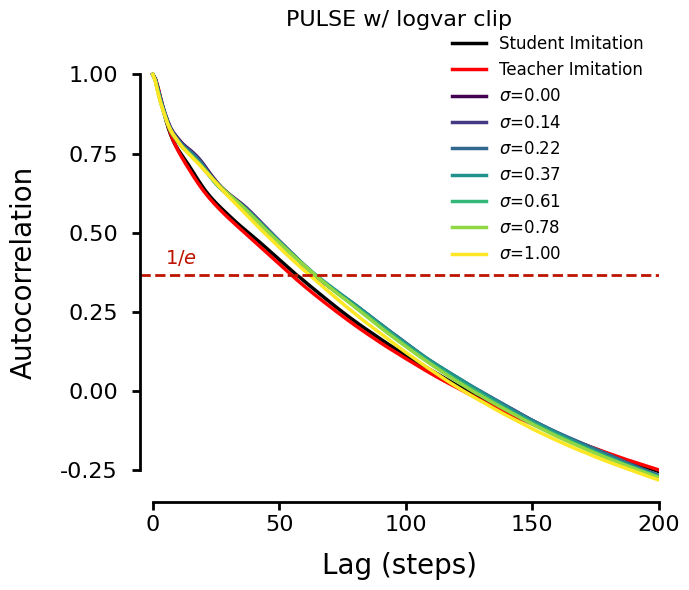

In [11]:
# Autocorrelation decay curves for PULSE w/ logvar clip
clamp_ac_gen_no_teacher = [
    n for n in clamp_ac_generated_names if n != DISTILL_TEACHER_DATASET
]
clamp_n_gen = len(clamp_ac_gen_no_teacher)
clamp_cmap = cm.get_cmap("viridis", clamp_n_gen)

clamp_ac_gen_sorted = sorted(clamp_ac_gen_no_teacher, key=distill_ac_sort_key)

clamp_ac_colors = {CLAMP_REFERENCE_DATASET: "black"}
if DISTILL_TEACHER_DATASET in clamp_ac_generated_names:
    clamp_ac_colors[DISTILL_TEACHER_DATASET] = "red"
for i, name in enumerate(clamp_ac_gen_sorted):
    clamp_ac_colors[name] = clamp_cmap(i)

clamp_ac_plot_order = [CLAMP_REFERENCE_DATASET]
if DISTILL_TEACHER_DATASET in clamp_ac_generated_names:
    clamp_ac_plot_order.append(DISTILL_TEACHER_DATASET)
clamp_ac_plot_order += clamp_ac_gen_sorted

fig, ax = plt.subplots(figsize=(7, 6))

for name in clamp_ac_plot_order:
    label = distill_ac_label_map.get(name, name)
    mean = clamp_ac_stats[name]["mean"]
    color = clamp_ac_colors[name]

    ax.plot(lags, mean, linewidth=2.5, color=color, label=label)

ax.set_xlabel("Lag (steps)", fontsize=20, labelpad=12)
ax.set_ylabel("Autocorrelation", fontsize=20, labelpad=16)
ax.tick_params(labelsize=16, width=2, length=6)
ax.tick_params(axis="y", pad=10)
ax.set_ylim(-0.35, 1.1)
ax.set_xlim(-5, MAX_LAG)

base_yticks = [-0.25, 0.0, 0.25, 0.5, 0.75, 1.0]
ax.set_yticks(base_yticks)
ax.set_yticklabels([f"{t:.2f}" for t in base_yticks])

sns.despine(ax=ax)

xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax.spines["left"].set_bounds(base_yticks[0], base_yticks[-1])

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

ax.axhline(1.0 / np.e, color=red_color, linestyle="--", alpha=1.0, linewidth=2)
ax.text(5, 1.0 / np.e + 0.02, "$1/e$", color=red_color, fontsize=14, va="bottom")

ax.legend(fontsize=12, frameon=False, loc="upper right", bbox_to_anchor=(1.0, 1.05))
ax.set_title("PULSE w/ logvar clip", fontsize=16, pad=12)

plt.tight_layout()
SAVE_DIR.mkdir(parents=True, exist_ok=True)
for fmt in ("pdf", "svg", "png"):
    fig.savefig(
        SAVE_DIR / f"autocorrelation_curves_clamp.{fmt}", bbox_inches="tight", dpi=150
    )
print(f"Saved clamp autocorrelation curves")
plt.show()

In [12]:
# Min autocorrelation (mean curve) for each distill dataset
print("=== PULSE w/o logvar clip ===")
for name in distill_ac_plot_order:
    label = distill_ac_label_map.get(name, name)
    min_val = distill_ac_stats[name]["mean"].min()
    min_lag = distill_ac_stats[name]["mean"].argmin()
    print(f"{label:>20s}: min autocorrelation = {min_val:.4f} at lag {min_lag}")

print("\n=== PULSE w/ logvar clip ===")
for name in clamp_ac_plot_order:
    label = distill_ac_label_map.get(name, name)
    min_val = clamp_ac_stats[name]["mean"].min()
    min_lag = clamp_ac_stats[name]["mean"].argmin()
    print(f"{label:>20s}: min autocorrelation = {min_val:.4f} at lag {min_lag}")

=== PULSE w/o logvar clip ===
   Student Imitation: min autocorrelation = -0.2573 at lag 200
   Teacher Imitation: min autocorrelation = -0.2490 at lag 200
       $\sigma$=0.00: min autocorrelation = -0.3449 at lag 200
       $\sigma$=0.14: min autocorrelation = -0.3461 at lag 200
       $\sigma$=0.22: min autocorrelation = -0.3317 at lag 200
       $\sigma$=0.37: min autocorrelation = -0.3206 at lag 200
       $\sigma$=0.61: min autocorrelation = -0.2816 at lag 200
       $\sigma$=0.78: min autocorrelation = -0.2647 at lag 200
       $\sigma$=1.00: min autocorrelation = -0.2091 at lag 200

=== PULSE w/ logvar clip ===
   Student Imitation: min autocorrelation = -0.2532 at lag 200
   Teacher Imitation: min autocorrelation = -0.2483 at lag 200
       $\sigma$=0.00: min autocorrelation = -0.2679 at lag 200
       $\sigma$=0.14: min autocorrelation = -0.2675 at lag 200
       $\sigma$=0.22: min autocorrelation = -0.2655 at lag 200
       $\sigma$=0.37: min autocorrelation = -0.2692 at lag

/tmp/ipykernel_521495/3142870341.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=distill_ac_labels, x=distill_ac_values, palette=distill_bar_colors, ax=ax)


Saved distill autocorrelation time bar plot


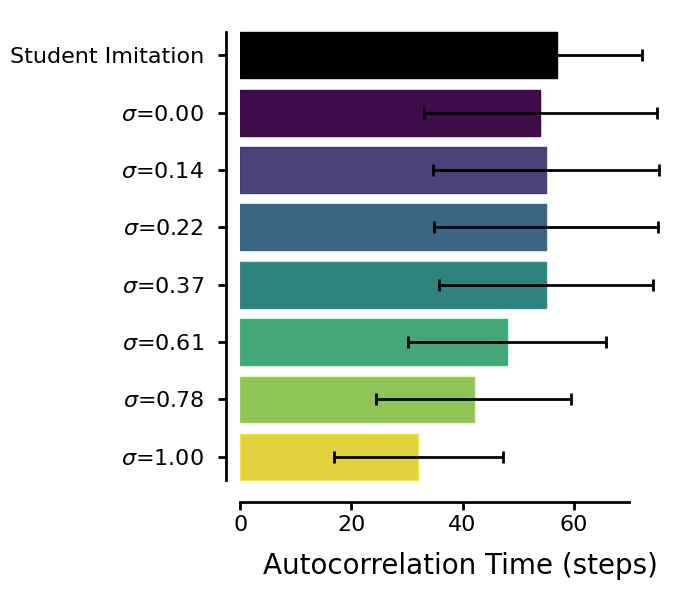

In [13]:
# Bar plot of distill autocorrelation times
distill_ac_bar_order = [DISTILL_REFERENCE_DATASET] + distill_ac_gen_sorted
distill_ac_bar_order = [n for n in distill_ac_bar_order if n in distill_ac_times]

distill_ac_labels = [distill_ac_label_map.get(n, n) for n in distill_ac_bar_order]
distill_ac_values = [distill_ac_times[n] for n in distill_ac_bar_order]
distill_ac_stds_list = [distill_ac_times_std[n] for n in distill_ac_bar_order]
distill_bar_colors = [distill_ac_colors[n] for n in distill_ac_bar_order]

fig, ax = plt.subplots(figsize=(7, 6))

sns.barplot(y=distill_ac_labels, x=distill_ac_values, palette=distill_bar_colors, ax=ax)

# Remove black outlines — set edgecolor to match facecolor
for patch, c in zip(ax.patches, distill_bar_colors):
    patch.set_edgecolor(c)

# Add error bars
bar_positions = sorted([patch.get_y() + patch.get_height() / 2 for patch in ax.patches])
ax.errorbar(
    distill_ac_values,
    bar_positions,
    xerr=distill_ac_stds_list,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

ax.set_xlabel("Autocorrelation Time (steps)", fontsize=20, labelpad=12)
ax.set_ylabel("")
ax.tick_params(labelsize=16, width=2, length=6)
ax.tick_params(axis="y", pad=10)

sns.despine(ax=ax)
ax.spines["left"].set_position(("outward", 10))

xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])

bar_positions_raw = sorted([p.get_y() for p in ax.patches])
ax.spines["left"].set_bounds(
    bar_positions_raw[0], bar_positions_raw[-1] + ax.patches[0].get_height()
)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()
for fmt in ("pdf", "svg", "png"):
    fig.savefig(SAVE_DIR / f"autocorrelation_time_distill.{fmt}", bbox_inches="tight")
print(f"Saved distill autocorrelation time bar plot")
plt.show()

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/autocorrelation_time_comparison.pdf and .svg


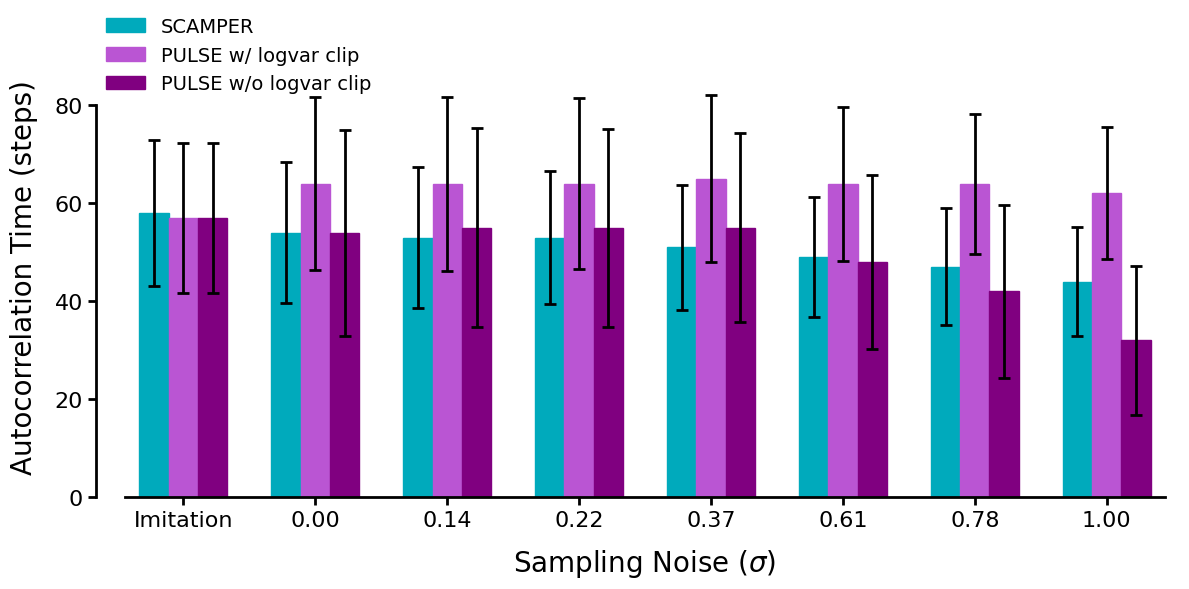

In [14]:
# Grouped vertical bar chart: SCAMPER vs PULSE w/ logvar clip vs PULSE w/o logvar clip
# Include imitation reference + shared sigma labels
ac_sigma_label_map = {
    "prior_deterministic_qpos": "0.00",
    "prior_logvar_-4_qpos": "0.14",
    "prior_logvar_-3_qpos": "0.22",
    "prior_logvar_-2_qpos": "0.37",
    "prior_logvar_-1_qpos": "0.61",
    "prior_logvar_-0.5_qpos": "0.78",
    "prior_logvar_0_qpos": "1.00",
}
ac_sigma_names = list(ac_sigma_label_map.keys())

# X-axis labels: Imitation first, then sigma values
ac_x_labels = ["Imitation"] + list(ac_sigma_label_map.values())

# SCAMPER values
scamper_ac_vals = [ac_times[REFERENCE_DATASET]] + [ac_times[n] for n in ac_sigma_names]
scamper_ac_errs = [ac_times_std[REFERENCE_DATASET]] + [
    ac_times_std[n] for n in ac_sigma_names
]

# PULSE w/o logvar clip values
pulse_ac_vals = [distill_ac_times[DISTILL_REFERENCE_DATASET]] + [
    distill_ac_times[n] for n in ac_sigma_names
]
pulse_ac_errs = [distill_ac_times_std[DISTILL_REFERENCE_DATASET]] + [
    distill_ac_times_std[n] for n in ac_sigma_names
]

# PULSE w/ logvar clip values
clamp_ac_vals = [clamp_ac_times[CLAMP_REFERENCE_DATASET]] + [
    clamp_ac_times[n] for n in ac_sigma_names
]
clamp_ac_errs = [clamp_ac_times_std[CLAMP_REFERENCE_DATASET]] + [
    clamp_ac_times_std[n] for n in ac_sigma_names
]

# Colors
bar_rgb = (0, 170, 188)
bar_color = tuple(c / 255 for c in bar_rgb)
purple_rgb = (128, 0, 128)
purple_color = tuple(c / 255 for c in purple_rgb)
light_purple_rgb = (186, 85, 211)
light_purple_color = tuple(c / 255 for c in light_purple_rgb)

save_name_ac_cmp = "autocorrelation_time_comparison"

fig, ax = plt.subplots(figsize=(12, 6))

n = len(ac_x_labels)
x = np.arange(n) * 1.8  # spread out for 3 bars
bar_width = 0.4

# SCAMPER bars (left)
ax.bar(
    x - bar_width,
    scamper_ac_vals,
    bar_width,
    color=bar_color,
    edgecolor=bar_color,
    label="SCAMPER",
)
ax.errorbar(
    x - bar_width,
    scamper_ac_vals,
    yerr=scamper_ac_errs,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

# PULSE w/ logvar clip bars (center)
ax.bar(
    x,
    clamp_ac_vals,
    bar_width,
    color=light_purple_color,
    edgecolor=light_purple_color,
    label="PULSE w/ logvar clip",
)
ax.errorbar(
    x,
    clamp_ac_vals,
    yerr=clamp_ac_errs,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

# PULSE w/o logvar clip bars (right)
ax.bar(
    x + bar_width,
    pulse_ac_vals,
    bar_width,
    color=purple_color,
    edgecolor=purple_color,
    label="PULSE w/o logvar clip",
)
ax.errorbar(
    x + bar_width,
    pulse_ac_vals,
    yerr=pulse_ac_errs,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

ax.set_xticks(x)
ax.set_xticklabels(ac_x_labels)
ax.set_xlim(x[0] - 1.0, x[-1] + 1.0)

y_max = max(
    max(v + e for v, e in zip(scamper_ac_vals, scamper_ac_errs)),
    max(v + e for v, e in zip(pulse_ac_vals, pulse_ac_errs)),
    max(v + e for v, e in zip(clamp_ac_vals, clamp_ac_errs)),
)
ax.set_ylim(0, y_max * 1.1)

ax.set_ylabel("Autocorrelation Time (steps)", fontsize=20, labelpad=12)
ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=14, frameon=False, loc="center left", bbox_to_anchor=(-0.02, 1.0))

sns.despine(ax=ax)
ax.spines["left"].set_position(("outward", 10))

yticks = ax.get_yticks()
ylim = ax.get_ylim()
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]
ax.spines["left"].set_bounds(yticks[0], yticks[-1])

ax.spines["bottom"].set_bounds(x[0] - 0.8, x[-1] + 0.8)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

SAVE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(SAVE_DIR / f"{save_name_ac_cmp}.pdf", bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{save_name_ac_cmp}.svg", bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{save_name_ac_cmp}.png", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / save_name_ac_cmp}.pdf and .svg")

plt.show()

In [15]:
# Statistical significance: Welch's t-test on per-clip autocorrelation times
# SCAMPER vs PULSE w/o logvar clip vs PULSE w/ logvar clip
from scipy import stats

# Recompute per-clip autocorrelation times (needed for t-test, not just mean/std)
scamper_per_clip_ac_times = {}
pulse_per_clip_ac_times = {}
clamp_per_clip_ac_times = {}


def _valid_per_clip_times(per_clip):
    """Extract per-clip autocorrelation times, skipping clips with insufficient data."""
    valid_mask = ~np.isnan(per_clip[:, 0])
    return np.array([autocorrelation_time(c) for c in per_clip[valid_mask]])


# Imitation
scamper_clips = compute_autocorrelation_per_clip(
    ac_qpos[REFERENCE_DATASET], MAX_LAG, ac_valid_lengths[REFERENCE_DATASET]
)
scamper_per_clip_ac_times["Imitation"] = _valid_per_clip_times(scamper_clips)

pulse_clips = compute_autocorrelation_per_clip(
    distill_ac_qpos[DISTILL_REFERENCE_DATASET],
    MAX_LAG,
    distill_valid_lengths[DISTILL_REFERENCE_DATASET],
)
pulse_per_clip_ac_times["Imitation"] = _valid_per_clip_times(pulse_clips)

clamp_clips = compute_autocorrelation_per_clip(
    clamp_ac_qpos[CLAMP_REFERENCE_DATASET],
    MAX_LAG,
    clamp_valid_lengths[CLAMP_REFERENCE_DATASET],
)
clamp_per_clip_ac_times["Imitation"] = _valid_per_clip_times(clamp_clips)

# Prior sigmas
for name, label in ac_sigma_label_map.items():
    scamper_clips = compute_autocorrelation_per_clip(
        ac_qpos[name], MAX_LAG, ac_valid_lengths[name]
    )
    scamper_per_clip_ac_times[label] = _valid_per_clip_times(scamper_clips)

    pulse_clips = compute_autocorrelation_per_clip(
        distill_ac_qpos[name], MAX_LAG, distill_valid_lengths[name]
    )
    pulse_per_clip_ac_times[label] = _valid_per_clip_times(pulse_clips)

    clamp_clips = compute_autocorrelation_per_clip(
        clamp_ac_qpos[name], MAX_LAG, clamp_valid_lengths[name]
    )
    clamp_per_clip_ac_times[label] = _valid_per_clip_times(clamp_clips)

# Run Welch's t-test for each pair
all_labels = ["Imitation"] + list(ac_sigma_label_map.values())

print("SCAMPER vs PULSE w/o logvar clip")
print(
    f"{'Label':>12s}  {'SCAMPER':>16s}  {'PULSE w/o':>16s}  {'t-stat':>8s}  {'p-value':>10s}  {'Sig?':>5s}"
)
print("-" * 80)
for label in all_labels:
    s = scamper_per_clip_ac_times[label]
    p = pulse_per_clip_ac_times[label]
    t_stat, p_val = stats.ttest_ind(s, p, equal_var=False)
    sig = (
        "***"
        if p_val < 0.001
        else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"
    )
    print(
        f"{label:>12s}  "
        f"{s.mean():6.1f} +/- {s.std():5.1f}  "
        f"{p.mean():6.1f} +/- {p.std():5.1f}  "
        f"{t_stat:8.2f}  "
        f"{p_val:10.2e}  "
        f"{sig:>5s}"
    )

print("\nSCAMPER vs PULSE w/ logvar clip")
print(
    f"{'Label':>12s}  {'SCAMPER':>16s}  {'PULSE w/':>16s}  {'t-stat':>8s}  {'p-value':>10s}  {'Sig?':>5s}"
)
print("-" * 80)
for label in all_labels:
    s = scamper_per_clip_ac_times[label]
    c = clamp_per_clip_ac_times[label]
    t_stat, p_val = stats.ttest_ind(s, c, equal_var=False)
    sig = (
        "***"
        if p_val < 0.001
        else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"
    )
    print(
        f"{label:>12s}  "
        f"{s.mean():6.1f} +/- {s.std():5.1f}  "
        f"{c.mean():6.1f} +/- {c.std():5.1f}  "
        f"{t_stat:8.2f}  "
        f"{p_val:10.2e}  "
        f"{sig:>5s}"
    )

print("\nPULSE w/o logvar clip vs PULSE w/ logvar clip")
print(
    f"{'Label':>12s}  {'PULSE w/o':>16s}  {'PULSE w/':>16s}  {'t-stat':>8s}  {'p-value':>10s}  {'Sig?':>5s}"
)
print("-" * 80)
for label in all_labels:
    p = pulse_per_clip_ac_times[label]
    c = clamp_per_clip_ac_times[label]
    t_stat, p_val = stats.ttest_ind(p, c, equal_var=False)
    sig = (
        "***"
        if p_val < 0.001
        else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"
    )
    print(
        f"{label:>12s}  "
        f"{p.mean():6.1f} +/- {p.std():5.1f}  "
        f"{c.mean():6.1f} +/- {c.std():5.1f}  "
        f"{t_stat:8.2f}  "
        f"{p_val:10.2e}  "
        f"{sig:>5s}"
    )

/tmp/ipykernel_521495/901338107.py:57: RuntimeWarning: Mean of empty slice
  return np.nanmean(ac_curves, axis=1)


SCAMPER vs PULSE w/o logvar clip
       Label           SCAMPER         PULSE w/o    t-stat     p-value   Sig?
--------------------------------------------------------------------------------
   Imitation    57.3 +/-  14.9    57.3 +/-  15.3      0.05    9.59e-01     ns
        0.00    51.9 +/-  14.3    59.9 +/-  21.0     -9.08    3.48e-19    ***
        0.14    51.4 +/-  14.5    60.8 +/-  20.4    -10.99    4.50e-27    ***
        0.22    51.7 +/-  13.6    60.8 +/-  20.2    -10.83    2.28e-26    ***
        0.37    50.6 +/-  12.8    60.1 +/-  19.3    -11.90    3.13e-31    ***
        0.61    48.7 +/-  12.2    54.3 +/-  17.8     -7.59    5.53e-14    ***
        0.78    47.3 +/-  11.9    49.2 +/-  17.6     -2.65    8.11e-03     **
        1.00    44.5 +/-  11.1    39.2 +/-  15.2      8.15    7.18e-16    ***

SCAMPER vs PULSE w/ logvar clip
       Label           SCAMPER          PULSE w/    t-stat     p-value   Sig?
-------------------------------------------------------------------------

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/autocorrelation_time_comparison_sig.pdf and .svg


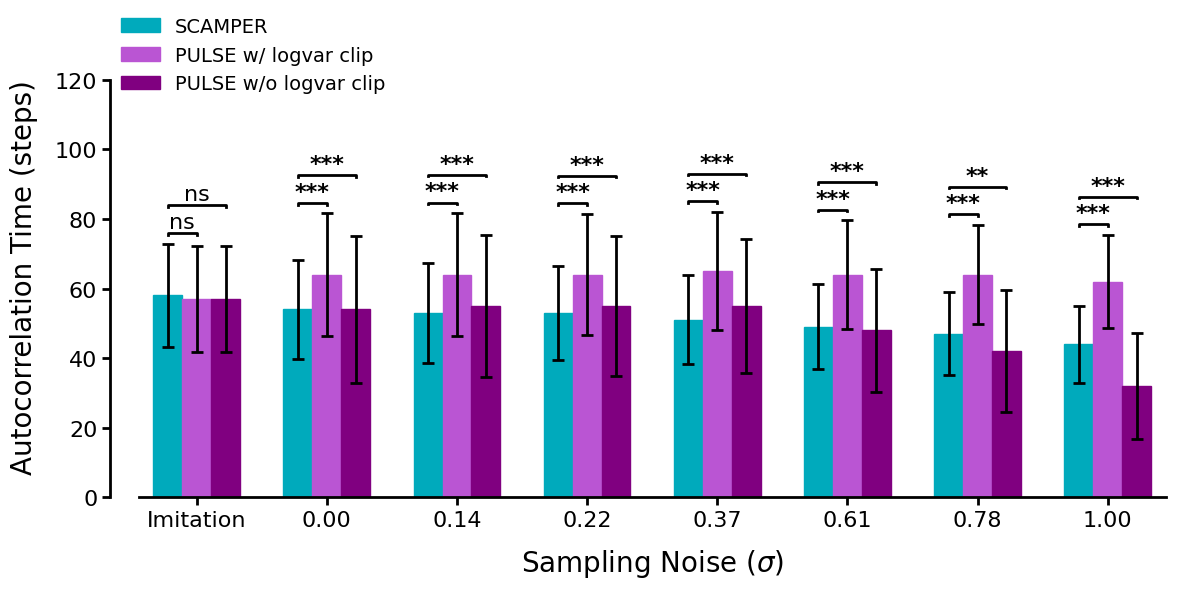

In [16]:
# Replot with significance brackets (3 groups)
save_name_ac_cmp_sig = "autocorrelation_time_comparison_sig"

fig, ax = plt.subplots(figsize=(12, 6))

n = len(ac_x_labels)
x = np.arange(n) * 1.8
bar_width = 0.4

# SCAMPER bars (left)
ax.bar(
    x - bar_width,
    scamper_ac_vals,
    bar_width,
    color=bar_color,
    edgecolor=bar_color,
    label="SCAMPER",
)
ax.errorbar(
    x - bar_width,
    scamper_ac_vals,
    yerr=scamper_ac_errs,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

# PULSE w/ logvar clip bars (center)
ax.bar(
    x,
    clamp_ac_vals,
    bar_width,
    color=light_purple_color,
    edgecolor=light_purple_color,
    label="PULSE w/ logvar clip",
)
ax.errorbar(
    x,
    clamp_ac_vals,
    yerr=clamp_ac_errs,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

# PULSE w/o logvar clip bars (right)
ax.bar(
    x + bar_width,
    pulse_ac_vals,
    bar_width,
    color=purple_color,
    edgecolor=purple_color,
    label="PULSE w/o logvar clip",
)
ax.errorbar(
    x + bar_width,
    pulse_ac_vals,
    yerr=pulse_ac_errs,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

# Add significance brackets
all_labels = ["Imitation"] + list(ac_sigma_label_map.values())
for i, label in enumerate(all_labels):
    s = scamper_per_clip_ac_times[label]
    p = pulse_per_clip_ac_times[label]
    c = clamp_per_clip_ac_times[label]

    # Heights of each bar + error
    y_scamper = scamper_ac_vals[i] + scamper_ac_errs[i]
    y_clamp = clamp_ac_vals[i] + clamp_ac_errs[i]
    y_pulse = pulse_ac_vals[i] + pulse_ac_errs[i]
    y_top = max(y_scamper, y_clamp, y_pulse)

    # Bracket 1: SCAMPER vs PULSE w/ logvar clip (adjacent bars)
    _, p_val_sc = stats.ttest_ind(s, c, equal_var=False)
    sig_sc = (
        "***"
        if p_val_sc < 0.001
        else "**" if p_val_sc < 0.01 else "*" if p_val_sc < 0.05 else "ns"
    )

    y_b1 = y_top + 3
    x_l1 = x[i] - bar_width
    x_r1 = x[i]
    ax.plot(
        [x_l1, x_l1, x_r1, x_r1],
        [y_b1 - 0.5, y_b1, y_b1, y_b1 - 0.5],
        color="black",
        linewidth=2,
    )
    fw = "normal" if sig_sc == "ns" else "bold"
    ax.text(
        (x_l1 + x_r1) / 2,
        y_b1 + 0.3,
        sig_sc,
        ha="center",
        va="bottom",
        fontsize=16,
        fontweight=fw,
    )

    # Bracket 2: SCAMPER vs PULSE w/o logvar clip (outermost bars)
    _, p_val_sp = stats.ttest_ind(s, p, equal_var=False)
    sig_sp = (
        "***"
        if p_val_sp < 0.001
        else "**" if p_val_sp < 0.01 else "*" if p_val_sp < 0.05 else "ns"
    )

    y_b2 = y_b1 + 8
    x_l2 = x[i] - bar_width
    x_r2 = x[i] + bar_width
    ax.plot(
        [x_l2, x_l2, x_r2, x_r2],
        [y_b2 - 0.5, y_b2, y_b2, y_b2 - 0.5],
        color="black",
        linewidth=2,
    )
    fw = "normal" if sig_sp == "ns" else "bold"
    ax.text(
        (x_l2 + x_r2) / 2,
        y_b2 + 0.3,
        sig_sp,
        ha="center",
        va="bottom",
        fontsize=16,
        fontweight=fw,
    )

ax.set_xticks(x)
ax.set_xticklabels(ac_x_labels)
ax.set_xlim(x[0] - 1.0, x[-1] + 1.0)

# Extend y-axis to fit brackets
y_max = max(
    max(v + e for v, e in zip(scamper_ac_vals, scamper_ac_errs)),
    max(v + e for v, e in zip(pulse_ac_vals, pulse_ac_errs)),
    max(v + e for v, e in zip(clamp_ac_vals, clamp_ac_errs)),
)
ax.set_ylim(0, y_max * 1.55)

ax.set_ylabel("Autocorrelation Time (steps)", fontsize=20, labelpad=12)
ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=14, frameon=False, loc="center left", bbox_to_anchor=(-0.02, 1.0))

sns.despine(ax=ax)
ax.spines["left"].set_position(("outward", 10))

yticks = ax.get_yticks()
ylim = ax.get_ylim()
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]
ax.spines["left"].set_bounds(yticks[0], yticks[-1])

ax.spines["bottom"].set_bounds(x[0] - 0.8, x[-1] + 0.8)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

SAVE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(SAVE_DIR / f"{save_name_ac_cmp_sig}.pdf", bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{save_name_ac_cmp_sig}.svg", bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{save_name_ac_cmp_sig}.png", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / save_name_ac_cmp_sig}.pdf and .svg")

plt.show()

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/autocorrelation_time_vs_sigma


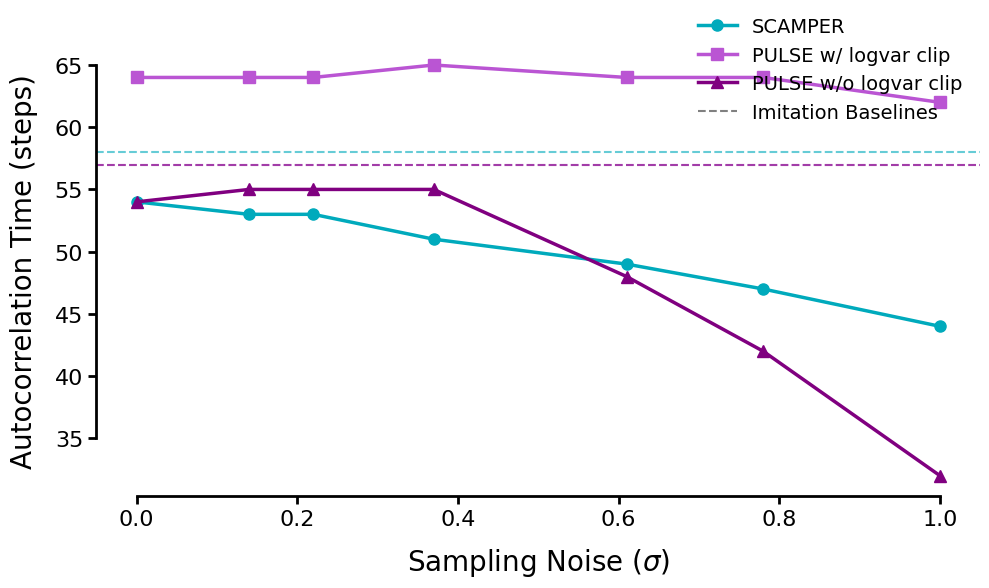

In [17]:
# Line plot: autocorrelation time vs sigma, with imitation baselines
save_name_line = "autocorrelation_time_vs_sigma"

sigma_floats = [float(v) for v in ac_sigma_label_map.values()]

# Values for each model at each sigma
scamper_sigma_vals = [ac_times[n] for n in ac_sigma_names]
clamp_sigma_vals = [clamp_ac_times[n] for n in ac_sigma_names]
pulse_sigma_vals = [distill_ac_times[n] for n in ac_sigma_names]

# Imitation baselines
scamper_imit = ac_times[REFERENCE_DATASET]
clamp_imit = clamp_ac_times[CLAMP_REFERENCE_DATASET]
pulse_imit = distill_ac_times[DISTILL_REFERENCE_DATASET]

fig, ax = plt.subplots(figsize=(10, 6))

# Lines
ax.plot(
    sigma_floats,
    scamper_sigma_vals,
    "o-",
    color=bar_color,
    linewidth=2.5,
    markersize=8,
    label="SCAMPER",
)
ax.plot(
    sigma_floats,
    clamp_sigma_vals,
    "s-",
    color=light_purple_color,
    linewidth=2.5,
    markersize=8,
    label="PULSE w/ logvar clip",
)
ax.plot(
    sigma_floats,
    pulse_sigma_vals,
    "^-",
    color=purple_color,
    linewidth=2.5,
    markersize=8,
    label="PULSE w/o logvar clip",
)

# Imitation baselines (dashed, in each model's color)
ax.axhline(scamper_imit, color=bar_color, linestyle="--", linewidth=1.5, alpha=0.6)
ax.axhline(
    clamp_imit, color=light_purple_color, linestyle="--", linewidth=1.5, alpha=0.6
)
ax.axhline(pulse_imit, color=purple_color, linestyle="--", linewidth=1.5, alpha=0.6)

# Dummy line for legend entry
ax.plot(
    [], [], color="gray", linestyle="--", linewidth=1.5, label="Imitation Baselines"
)

ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.set_ylabel("Autocorrelation Time (steps)", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=14, frameon=False, loc="upper right", bbox_to_anchor=(1.0, 1.10))

sns.despine(ax=ax)

# Trim spines to tick range so they don't meet at the corner
xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])

yticks = ax.get_yticks()
ylim = ax.get_ylim()
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]
ax.spines["left"].set_bounds(yticks[0], yticks[-1])

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

SAVE_DIR.mkdir(parents=True, exist_ok=True)
for fmt in ("pdf", "svg", "png"):
    fig.savefig(SAVE_DIR / f"{save_name_line}.{fmt}", bbox_inches="tight", dpi=150)
print(f"Saved to {SAVE_DIR / save_name_line}")
plt.show()